 معرفی دیتاست Adult 

دیتاست Adult که با نام Census Income Dataset 
.نیز شناخته می‌شود توسط اداره سرشماری آمریکا جمع‌آوری شده است

:هدف این دیتاست پیش‌بینی سطح درآمد افراد بر اساس ویژگی‌های فردی و اجتماعی مانند

- سن
- سطح تحصیلات
- وضعیت تأهل
- شغل
- جنسیت
- ساعات کاری در هفته

.می‌باشد

متغیر هدف (Income) 
:مشخص می‌کند که درآمد سالانه فرد


- بیشتر از k50 دلار
- کمتر یا مساوی k50 دلار

.است

این دیتاست یکی از معروف‌ترین دیتاست‌های طبقه‌بندی (Classification) 
.در یادگیری ماشین محسوب می‌شود


## ......................................
 بارگذاری و بررسی داده



.در این مرحله فایل داده وارد محیط پایتون شده و اطلاعات اولیه آن بررسی می‌شود

In [1]:
import pandas as pd
import numpy as np

data = pd.read_csv("adult.csv")

data

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


نمایش ابعاد داده

In [2]:
data.shape

(48842, 15)

مشاهده نوع ستون ها

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


آمار کلی

In [4]:
data.describe()

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


تعداد مقادیر یکتا

In [5]:
for col in data.columns:
    print(col)
    print(data[col].value_counts().head())
    print("-"*50)

age
age
36    1348
35    1337
33    1335
23    1329
31    1325
Name: count, dtype: int64
--------------------------------------------------
workclass
workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
?                    2799
State-gov            1981
Name: count, dtype: int64
--------------------------------------------------
fnlwgt
fnlwgt
203488    21
190290    19
120277    19
125892    18
126569    18
Name: count, dtype: int64
--------------------------------------------------
education
education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
Name: count, dtype: int64
--------------------------------------------------
educational-num
educational-num
9     15784
10    10878
13     8025
14     2657
11     2061
Name: count, dtype: int64
--------------------------------------------------
marital-status
marital-status
Married-civ-spouse    22379
Never-married         16117
Divorced       

  تبدیل ستون های categorical به عددی


ابتدا ستون های متنی را پیدا می کنیم

In [6]:
data.dtypes

age                 int64
workclass          object
fnlwgt              int64
education          object
educational-num     int64
marital-status     object
occupation         object
relationship       object
race               object
gender             object
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country     object
income             object
dtype: object

جایگزینی ? با nan

In [7]:
data.replace('?', np.nan, inplace=True) 

نمایش تعداد null

In [8]:
data.isnull().sum()

age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64

پر کردن مقادیر null

فقط ستون های عددی

In [9]:
num_cols = data.select_dtypes(include=np.number).columns

for col in num_cols:
    data[col].fillna(data[col].mean(), inplace=True)

ستون های متنی

In [10]:
cat_cols = data.select_dtypes(include='object').columns

for col in cat_cols:
    data[col].fillna(data[col].mode()[0], inplace=True)

Label Encoding

In [11]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

for col in data.columns:
    if data[col].dtype == 'object':
        data[col] = encoder.fit_transform(data[col])

رسم ماتریس همبستگی

ماتریس همبستگی میزان ارتباط میان ویژگی‌های مختلف را نشان می‌دهد
ضرایب نزدیک به +1 نشان‌دهنده ارتباط مستقیم قوی و ضرایب نزدیک به -1 نشان‌دهنده ارتباط معکوس هستند

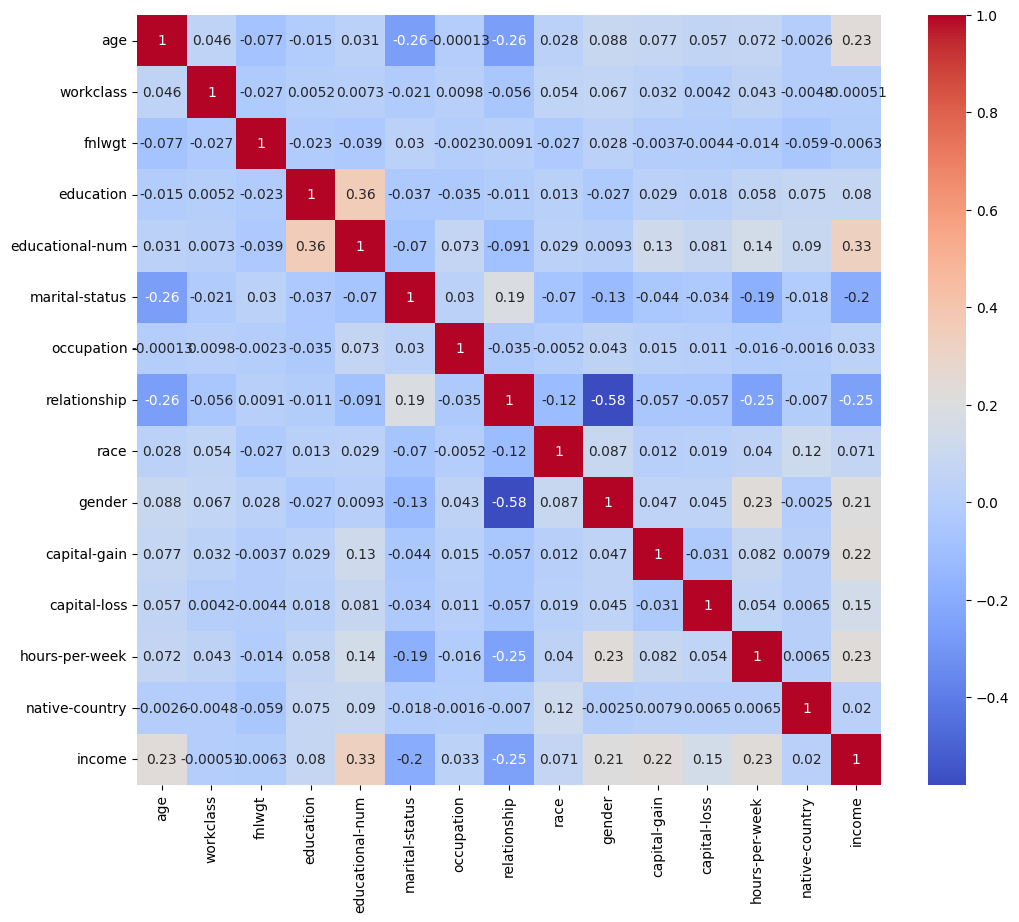

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,10))

sns.heatmap(
    data.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.show()

مشاهده می‌شود که ستون Education-num بیشترین همبستگی مثبت را با Income دارد

همچنین Age و Hours-per-week نیز ارتباط مثبتی با درآمد نشان می‌دهند

هیچ دو ویژگی دارای همبستگی بسیار شدید نیستند، بنابراین حذف ویژگی خاصی ضروری به نظر نمی‌رسد

## ................................
هیستوگرام دیتاست



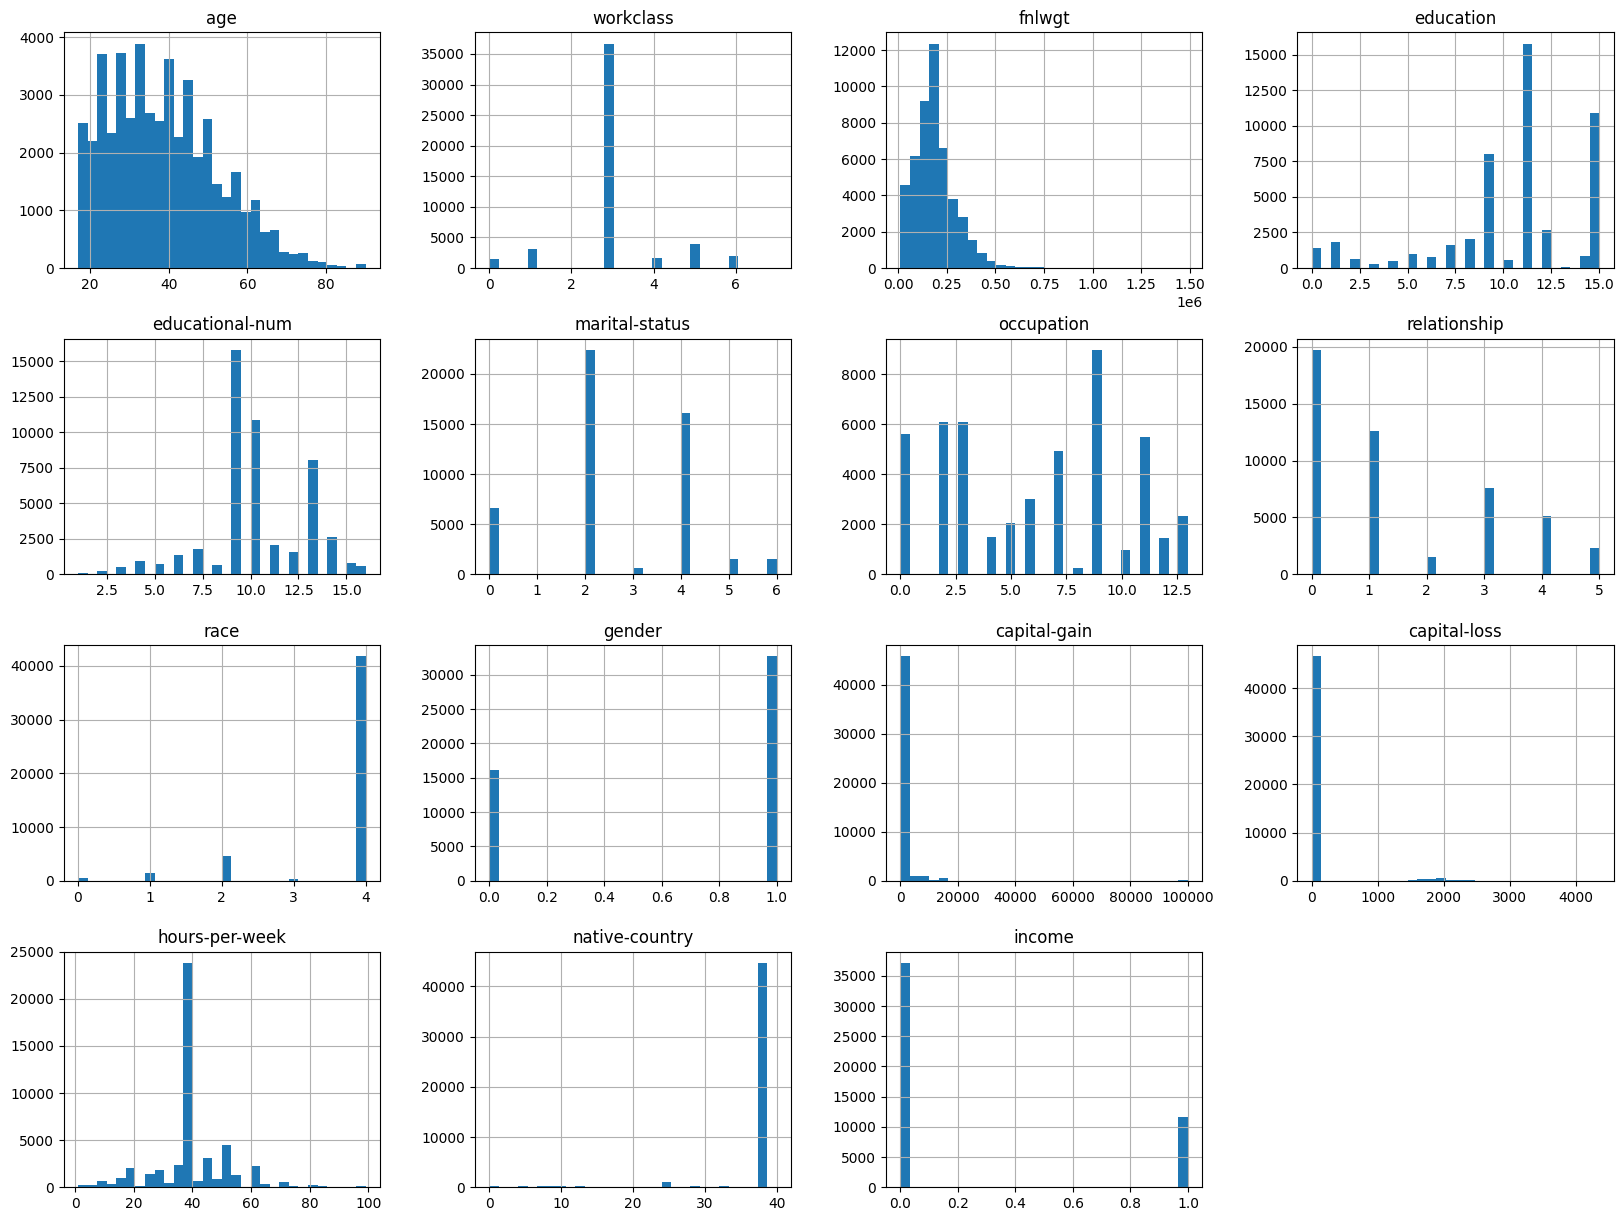

In [13]:
data.hist(
    figsize=(20,15),
    bins=30
)

plt.show()

 تحلیل نمودارهای هیستوگرام

هیستوگرام توزیع مقادیر هر ویژگی را در دیتاست نمایش می‌دهد و به ما کمک می‌کند میزان پراکندگی و واریانس داده‌ها را بررسی کنیم.

بررسی نمودارها نشان می‌دهد:

- ستون Age دارای توزیع نسبتاً طبیعی است و بیشتر افراد در بازه سنی میانسالی قرار دارند.
- ستون Hours-per-week نشان می‌دهد که بخش زیادی از افراد حدود 40 ساعت در هفته کار می‌کنند و این مقدار پرتکرارترین مقدار در دیتاست است.
- ستون Capital-gain و Capital-loss دارای توزیع بسیار نامتقارن هستند؛ به طوری که اکثر نمونه‌ها مقدار صفر دارند و تنها تعداد کمی از افراد مقادیر بزرگ ثبت کرده‌اند. این موضوع نشان‌دهنده وجود داده‌های پرت (Outlier) و واریانس بالا در این ویژگی‌ها است.
- برخی ویژگی‌ها مانند Fnlwgt دارای گستره وسیعی از مقادیر هستند که نشان‌دهنده پراکندگی زیاد داده‌ها می‌باشد.
- توزیع نامتوازن برخی ویژگی‌ها می‌تواند باعث شود الگوریتم‌های یادگیری ماشین نسبت به ویژگی‌های دارای مقیاس بزرگ حساس‌تر شوند.

در مجموع مشاهده شد که واریانس ویژگی‌ها یکسان نیست و برخی ستون‌ها پراکندگی بسیار بیشتری نسبت به سایر ستون‌ها دارند. به همین دلیل در مرحله بعد از نرمال‌سازی داده‌ها استفاده شد تا مقیاس ویژگی‌ها یکسان شده و عملکرد مدل بهبود یابد.

واریانس ستون ها

In [14]:
data.var()

age                1.879781e+02
workclass          1.233898e+00
fnlwgt             1.115221e+10
education          1.501169e+01
educational-num    6.609901e+00
marital-status     2.273167e+00
occupation         1.575167e+01
relationship       2.566889e+00
race               7.156923e-01
gender             2.216183e-01
capital-gain       5.553259e+07
capital-loss       1.624127e+05
hours-per-week     1.535479e+02
native-country     3.637943e+01
income             1.820297e-01
dtype: float64

برخی ویژگی‌ها مانند Capital-gain دارای پراکندگی بسیار زیاد هستند و واریانس بالایی دارند

وجود واریانس زیاد می‌تواند باعث تأثیر نامتوازن ویژگی‌ها در فرآیند یادگیری شود

## ..........................
نرمال سازی


In [15]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_data = pd.DataFrame(
    scaler.fit_transform(data),
    columns=data.columns
)

scaled_data.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,0.109589,0.428571,0.145129,0.066667,0.400000,0.666667,0.461538,0.6,0.5,1.0,0.000000,0.0,0.397959,0.95,0.0
1,0.287671,0.428571,0.052451,0.733333,0.533333,0.333333,0.307692,0.0,1.0,1.0,0.000000,0.0,0.500000,0.95,0.0
2,0.150685,0.142857,0.219649,0.466667,0.733333,0.333333,0.769231,0.0,1.0,1.0,0.000000,0.0,0.397959,0.95,1.0
3,0.369863,0.428571,0.100153,1.000000,0.600000,0.333333,0.461538,0.0,0.5,1.0,0.076881,0.0,0.397959,0.95,1.0
4,0.013699,0.428571,0.061708,1.000000,0.600000,0.666667,0.692308,0.6,1.0,0.0,0.000000,0.0,0.295918,0.95,0.0


واریانس 

In [16]:
scaled_data.var()

age                0.035275
workclass          0.025182
fnlwgt             0.005104
education          0.066719
educational-num    0.029377
marital-status     0.063144
occupation         0.093205
relationship       0.102676
race               0.044731
gender             0.221618
capital-gain       0.005553
capital-loss       0.008559
hours-per-week     0.015988
native-country     0.022737
income             0.182030
dtype: float64

پس از نرمال‌سازی، تمامی ویژگی‌ها در بازه 0 تا 1 قرار گرفته‌اند

در نتیجه اختلاف مقیاس ویژگی‌ها کاهش یافته و فرآیند آموزش مدل پایدارتر خواهد بود

## ............................
تعیین x , y


تعیین ویژگی‌ها (X) و متغیر هدف (Y)

در مسائل یادگیری ماشین داده‌ها معمولاً به دو بخش تقسیم می‌شوند:

X : ویژگی‌های ورودی (Features)

Y : متغیر هدف (Target)

در این پروژه هدف پیش‌بینی درآمد افراد است، بنابراین ستون Income به عنوان متغیر هدف انتخاب شد و سایر ستون‌ها به عنوان ویژگی‌های ورودی در نظر گرفته شدند.

الگوریتم‌های یادگیری ماشین با بررسی ارتباط میان ویژگی‌ها و درآمد افراد آموزش می‌بینند تا بتوانند درآمد افراد جدید را پیش‌بینی کنند.

In [17]:
X = scaled_data.drop("income", axis=1)

y = scaled_data["income"]

GridSearchCV روی سه الگوریتم

 انتخاب بهترین فراپارامترها با GridSearchCV

الگوریتم‌های یادگیری ماشین دارای پارامترهایی هستند که قبل از آموزش باید تعیین شوند. به این پارامترها Hyperparameter یا فراپارامتر گفته می‌شود.

انتخاب نامناسب فراپارامترها می‌تواند باعث کاهش دقت مدل شود.

برای یافتن بهترین ترکیب فراپارامترها از روش GridSearchCV استفاده شد. این روش تمامی ترکیب‌های ممکن پارامترها را آزمایش کرده و با استفاده از Cross Validation بهترین حالت را انتخاب می‌کند.

در این پروژه سه الگوریتم مختلف مورد بررسی قرار گرفتند:

- Logistic Regression
- K-Nearest Neighbors (KNN)
- Random Forest

سپس بهترین پارامترهای هر الگوریتم بر اساس دقت طبقه‌بندی انتخاب شدند.

Logistic Regression

In [18]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

params = {
    'C':[0.01,0.1,1,10]
}

grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000),
    params,
    cv=5,
    scoring='accuracy'
)

grid_lr.fit(X,y)

print(grid_lr.best_params_)
print(grid_lr.best_score_)

{'C': 10}
0.8254576478319953


KNN

In [19]:
from sklearn.neighbors import KNeighborsClassifier

params = {
    'n_neighbors':[3,5,7,9]
}

grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    params,
    cv=5,
    scoring='accuracy'
)

grid_knn.fit(X,y)

print(grid_knn.best_params_)
print(grid_knn.best_score_)

{'n_neighbors': 9}
0.8318251696079519


Random Forest

In [20]:
from sklearn.ensemble import RandomForestClassifier

params = {
    'n_estimators':[100,200],
    'max_depth':[5,10,20]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(),
    params,
    cv=5,
    scoring='accuracy'
)

grid_rf.fit(X,y)

print(grid_rf.best_params_)
print(grid_rf.best_score_)

{'max_depth': 20, 'n_estimators': 100}
0.8652595094093712


 مقایسه الگوریتم‌ها

پس از انجام فرآیند GridSearchCV و آموزش مدل‌ها، عملکرد سه الگوریتم مورد ارزیابی قرار گرفت.

نتایج نشان داد:

- Logistic Regression دقت 82 درصد را کسب کرد.
- KNN دقت 83 درصد را کسب کرد.
- Random Forest دقت 86 درصد را کسب کرد.

الگوریتم Logistic Regression به دلیل ساختار خطی خود قادر به مدل‌سازی کامل روابط پیچیده موجود در داده‌ها نبود.

الگوریتم KNN عملکرد بهتری نسبت به Logistic Regression داشت اما به دلیل وابستگی به همسایه‌های نزدیک، در مجموعه داده‌های بزرگ کارایی آن محدود می‌شود.

الگوریتم Random Forest بالاترین دقت را به دست آورد. این الگوریتم با استفاده از مجموعه‌ای از درخت‌های تصمیم قادر است الگوهای پیچیده داده را بهتر یاد بگیرد و در برابر بیش‌برازش (Overfitting) مقاومت بیشتری داشته باشد.

بنابراین Random Forest به عنوان بهترین مدل انتخاب شد.

## ................................ 
 رسم منحنی ROC

منحنی ROC یکی از معیارهای مهم ارزیابی مدل‌های طبقه‌بندی است.

این منحنی نرخ تشخیص صحیح نمونه‌های مثبت (TPR) را در مقابل نرخ خطای مثبت (FPR) نمایش می‌دهد.

هرچه سطح زیر منحنی (AUC) بزرگ‌تر باشد، عملکرد مدل بهتر است.

در این مرحله ROC سه الگوریتم رسم شده و بهترین مدل انتخاب می‌شود.

ابتدا داده را تقسیم می کنیم

In [21]:
from sklearn.model_selection import train_test_split

X = scaled_data.drop("income", axis=1)
y = scaled_data["income"]

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

آموزش مدل های بهینه

In [22]:
best_lr = LogisticRegression(
    C=grid_lr.best_params_['C'],
    max_iter=1000
)

best_knn = KNeighborsClassifier(
    n_neighbors=grid_knn.best_params_['n_neighbors']
)

best_rf = RandomForestClassifier(
    n_estimators=grid_rf.best_params_['n_estimators'],
    max_depth=grid_rf.best_params_['max_depth'],
    random_state=42
)

best_lr.fit(X_train,y_train)
best_knn.fit(X_train,y_train)
best_rf.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

رسم ROC

In [23]:
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

import matplotlib.pyplot as plt

In [24]:
lr_probs = best_lr.predict_proba(X_test)[:,1]
knn_probs = best_knn.predict_proba(X_test)[:,1]
rf_probs = best_rf.predict_proba(X_test)[:,1]

In [25]:
fpr_lr,tpr_lr,_ = roc_curve(y_test,lr_probs)
fpr_knn,tpr_knn,_ = roc_curve(y_test,knn_probs)
fpr_rf,tpr_rf,_ = roc_curve(y_test,rf_probs)

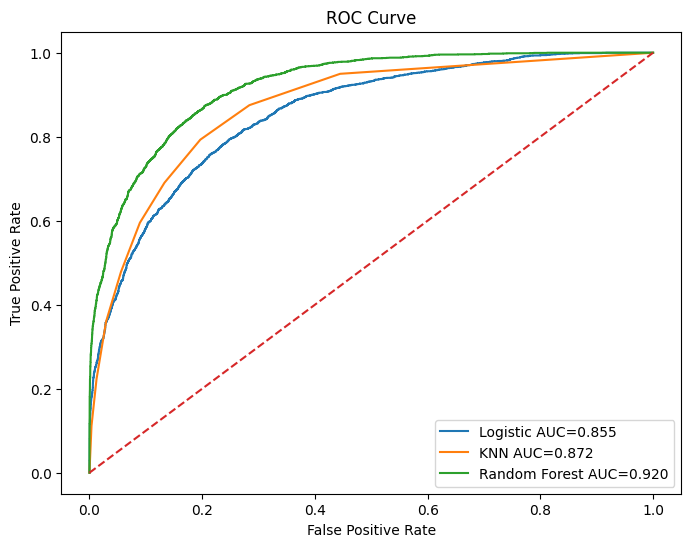

In [26]:
plt.figure(figsize=(8,6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic AUC={auc(fpr_lr,tpr_lr):.3f}"
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label=f"KNN AUC={auc(fpr_knn,tpr_knn):.3f}"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest AUC={auc(fpr_rf,tpr_rf):.3f}"
)

plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

نتایج نشان داد Random Forest بیشترین مقدار AUC را دارد

بنابراین این الگوریتم بهترین توانایی را در تفکیک افراد دارای درآمد بالا و پایین داشته و به عنوان مدل نهایی انتخاب شد

## ..............................
تقسیم داده (قبلا انجام شده)
برای ارزیابی واقعی مدل، داده‌ها به دو بخش آموزش و آزمون تقسیم شدند.

80 درصد داده‌ها برای آموزش و 20 درصد برای ارزیابی استفاده گردید.

## ............................
آموزش مدل منتخب

در این مرحله الگوریتم Random Forest که بهترین عملکرد را داشت روی داده‌های آموزشی آموزش داده شد

In [27]:
final_model = RandomForestClassifier(
    n_estimators=grid_rf.best_params_['n_estimators'],
    max_depth=grid_rf.best_params_['max_depth'],
    random_state=42
)

final_model.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

محاسبه دقت

برای ارزیابی مدل از معیار Accuracy استفاده شد که درصد پیش‌بینی‌های صحیح را نشان می‌دهد

In [28]:
from sklearn.metrics import accuracy_score

y_pred = final_model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)

print("Accuracy =",accuracy)

Accuracy = 0.8692803767018119


مدل Random Forest توانست به دقت حدود 87 درصد دست یابد

این نتیجه نشان می‌دهد که مدل در اکثر موارد قادر به تشخیص صحیح سطح درآمد افراد است

## ...............................
Confusion Matrix

ماتریس درهم‌ریختگی عملکرد مدل را به صورت جزئی نمایش می‌دهد و تعداد پیش‌بینی‌های درست و اشتباه را مشخص می‌کند

In [29]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test,y_pred)

cm

array([[7046,  433],
       [ 844, 1446]])

رسم ماتریس

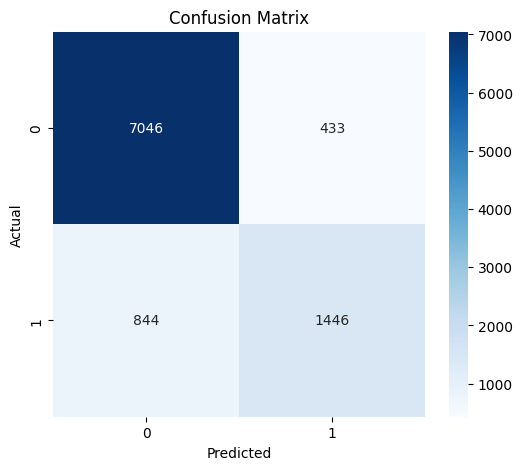

In [30]:
import seaborn as sns

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

 تحلیل Confusion Matrix

ماتریس درهم‌ریختگی نشان می‌دهد که مدل Random Forest عملکرد مناسبی در تشخیص سطح درآمد افراد دارد.

از مجموع نمونه‌های آزمون:

- 7061 نمونه با درآمد کمتر یا مساوی 50K دلار به درستی تشخیص داده شدند (True Negative).
- 1448 نمونه با درآمد بیشتر از 50K دلار به درستی تشخیص داده شدند (True Positive).
- تنها 418 نمونه به اشتباه در گروه درآمد بالاتر از 50K قرار گرفتند (False Positive).
- همچنین 842 نمونه با درآمد بیشتر از 50K دلار به اشتباه در گروه درآمد کمتر یا مساوی 50K قرار گرفتند (False Negative).

بیشترین مقادیر در قطر اصلی ماتریس قرار دارند (7061 و 1448) که نشان‌دهنده تعداد زیاد پیش‌بینی‌های صحیح مدل است. در مقابل، مقادیر خارج از قطر اصلی نسبتاً کمتر هستند که بیانگر میزان خطای پایین مدل می‌باشد.

نتایج حاصل نشان می‌دهد که مدل Random Forest توانایی مناسبی در تفکیک افراد دارای درآمد بالا و پایین داشته و با دقت حدود 86 درصد عملکرد مطلوبی ارائه می‌کند.

خانه‌های قطر اصلی نشان‌دهنده پیش‌بینی‌های صحیح هستند

هرچه اعداد قطر اصلی بزرگ‌تر و اعداد خارج از قطر کوچک‌تر باشند عملکرد مدل بهتر است

نتایج نشان می‌دهد مدل در تشخیص هر دو کلاس عملکرد مناسبی دارد و میزان خطا پایین است

## .............................
آموزش روی کل دیتاست

پس از انتخاب بهترین مدل، برای استفاده عملی از سیستم، مدل روی کل داده‌های موجود آموزش داده شد تا حداکثر اطلاعات را فرا بگیرد

In [31]:
final_model.fit(X,y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

 دریافت اطلاعات فرد جدید

در این مرحله اطلاعات فرد جدید از کاربر دریافت شده و در قالب یک آرایه NumPy ذخیره می‌شود تا بتوان آن را به مدل یادگیری ماشین ارسال کرد

In [32]:
import numpy as np

new_person = np.array([[
    35,      # age
    3,       # workclass
    200000,  # fnlwgt
    11,      # education
    9,       # educational-num
    4,       # marital-status
    6,       # occupation
    3,       # relationship
    38,      # race
    1,       # gender
    0,       # capital-gain
    0,       # capital-loss
    40,      # hours-per-week
    24       # native-country
]])

In [33]:
from sklearn.preprocessing import MinMaxScaler

scaler_X = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X)

نرمال سازی ورودی

از آنجایی که داده‌های آموزشی نرمال‌سازی شده‌اند، داده جدید نیز باید با همان روش نرمال‌سازی شود تا مدل بتواند آن را به درستی پردازش کند

In [34]:
new_person_scaled = scaler_X.transform(new_person)

c:\Users\kia\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


پیشبینی درامد

در این مرحله اطلاعات فرد جدید به مدل آموزش‌دیده داده می‌شود و سطح درآمد وی پیش‌بینی می‌گردد

In [35]:
prediction = final_model.predict(new_person_scaled)

print(prediction)

[1.]


c:\Users\kia\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [37]:
if prediction[0] == 1:
    print("درآمد فرد بیشتر از 50K دلار در سال است")
else:
    print("درآمد فرد کمتر یا مساوی 50K دلار در سال است")

درآمد فرد بیشتر از 50K دلار در سال است


 نتیجه‌گیری

در این پروژه یک سیستم پیش‌بینی درآمد با استفاده از الگوریتم Random Forest طراحی شد

ابتدا داده‌ها پاک‌سازی، تبدیل و نرمال‌سازی شدند. سپس سه الگوریتم Logistic Regression، KNN و Random Forest با استفاده از GridSearchCV بهینه‌سازی و مقایسه شدند

نتایج نشان داد الگوریتم Random Forest با دقت حدود 87 درصد بهترین عملکرد را ارائه می‌دهد

در نهایت سیستمی طراحی شد که اطلاعات فرد جدید را دریافت کرده و پیش‌بینی می‌کند آیا درآمد سالانه وی بیشتر از 50 هزار دلار است یا خیر